# 01 - Data Exploration

First look at the credit card fraud dataset (Kaggle: mlg-ulb/creditcardfraud).

## Setup

Add the project root to the path so we can import from `src`.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.data import load_data

## 1. Loading the data

Load the raw CSV with `load_data()`, which also checks the expected columns.

In [2]:
df = load_data()

### Shape

Number of rows (transactions) and columns (features + target).

In [3]:
df.shape

(284807, 31)

### Data types

Type of each column, to confirm everything is numeric as expected.

In [4]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

### First rows

A quick look at the raw values.

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Summary statistics

Count, mean, std, min, quartiles and max for each column.

In [6]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


### Missing values

Number of null values per column.

In [7]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

### Duplicate rows

Number of rows that are exact copies of another row.

In [8]:
df.duplicated().sum()

np.int64(1081)

## 2. Class imbalance

How many transactions are legitimate (`Class = 0`) versus fraud (`Class = 1`).

In [9]:
import pandas as pd

counts = df["Class"].value_counts().sort_index()
percent = df["Class"].value_counts(normalize=True).sort_index() * 100

pd.DataFrame({"count": counts, "percent": percent.round(3)})

,count,percent
Class,,
0,284315,99.827
1,492,0.173


### Class distribution (log scale)

A log scale is used because the fraud bar would be invisible on a linear scale.

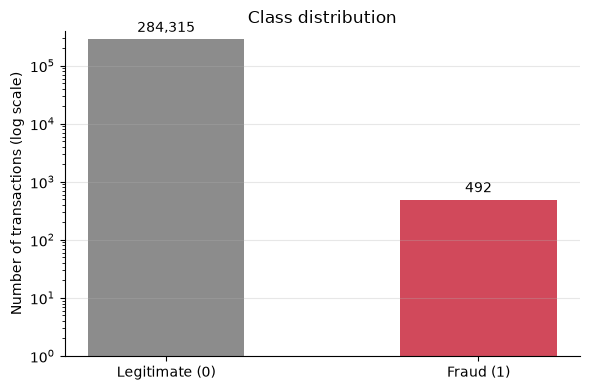

In [10]:
import matplotlib.pyplot as plt

labels = ["Legitimate (0)", "Fraud (1)"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=["#8c8c8c", "#d1495b"], width=0.5)
ax.set_yscale("log")
ax.set_ylim(bottom=1)
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class distribution")
ax.bar_label(bars, labels=[f"{c:,}" for c in counts.values], padding=3)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Why accuracy is misleading here

Only about 0.17% of transactions are fraud. A model that **always predicts "legitimate"** would reach about **99.8% accuracy** while catching **zero** frauds.

So accuracy says almost nothing about how well we detect fraud. Metrics that focus on the minority class are more useful, such as precision, recall, F1 and the area under the precision-recall curve (PR-AUC).

## 3. Amount and Time

How the transaction amount and the time of the transaction differ between classes.

### Distribution of log1p(Amount) by class

`Amount` is very skewed, so we plot `log1p(Amount)` (log of 1 + amount). Each class is shown as a density, so the very different class sizes can be compared.

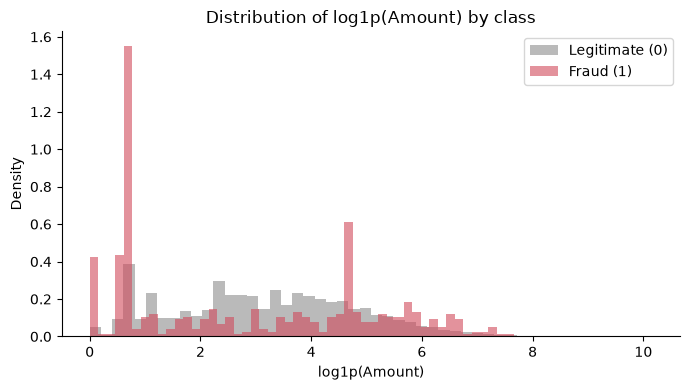

In [11]:
import numpy as np

fig, ax = plt.subplots(figsize=(7, 4))
for value, label, color in [(0, "Legitimate (0)", "#8c8c8c"), (1, "Fraud (1)", "#d1495b")]:
    amounts = np.log1p(df.loc[df["Class"] == value, "Amount"])
    ax.hist(amounts, bins=50, density=True, alpha=0.6, color=color, label=label)
ax.set_xlabel("log1p(Amount)")
ax.set_ylabel("Density")
ax.set_title("Distribution of log1p(Amount) by class")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Amount statistics by class

In [12]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


### Fraud rate by hour

`Time` is the number of seconds since the first transaction in the dataset, so `hour = (Time // 3600) % 24` is an hour relative to that start, not necessarily the real clock time.

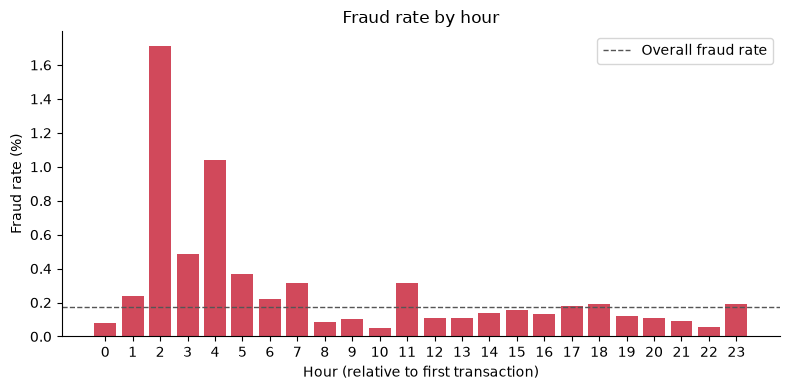

,transactions,frauds,fraud_rate
hour,,,
0,7695,6,0.077973
1,4220,10,0.236967
2,3328,57,1.712740
3,3492,17,0.486827
4,2209,23,1.041195
5,2990,11,0.367893
6,4101,9,0.219459
7,7243,23,0.317548
8,10276,9,0.087583


In [13]:
df["hour"] = (df["Time"] // 3600 % 24).astype(int)
hourly = df.groupby("hour")["Class"].agg(transactions="count", frauds="sum", fraud_rate="mean")
hourly["fraud_rate"] = hourly["fraud_rate"] * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(hourly.index, hourly["fraud_rate"], color="#d1495b", width=0.8)
ax.axhline(
    df["Class"].mean() * 100,
    color="#555555",
    linestyle="--",
    linewidth=1,
    label="Overall fraud rate",
)
ax.set_xticks(range(24))
ax.set_xlabel("Hour (relative to first transaction)")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by hour")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

hourly

### What we observe

- **Amount:** fraud amounts have a lower median (9.25 vs 22.00) but a higher mean (122.21 vs 88.29), and a smaller maximum (2,125.87 vs 25,691.16). Both classes overlap over most of the range.
- In the histogram, fraud shows a few sharp peaks at small values (log1p(Amount) near 0 and near 0.7, i.e. amounts around 0 and 1) and one near 4.7 (around 100). With only 492 frauds, these peaks are based on few transactions.
- **Hour:** the fraud rate is clearly higher in hours 2 and 4 (about 1.7% and 1.0%) than the overall rate (~0.17%). These hours also have far fewer transactions (around 2,200-3,500 vs ~16,000 in busier hours), so the rates are based on small counts.
- The dataset covers only two days and the hour is relative to the first transaction, so this does not prove a real time-of-day pattern.

## 4. Feature relationships

Which features are most related to `Class`, and how their values differ between classes.

### Top 10 features by absolute correlation with Class

Pearson correlation between each original feature and `Class`. The helper column `hour` is left out. Bars show the absolute value; the sign is in the table.

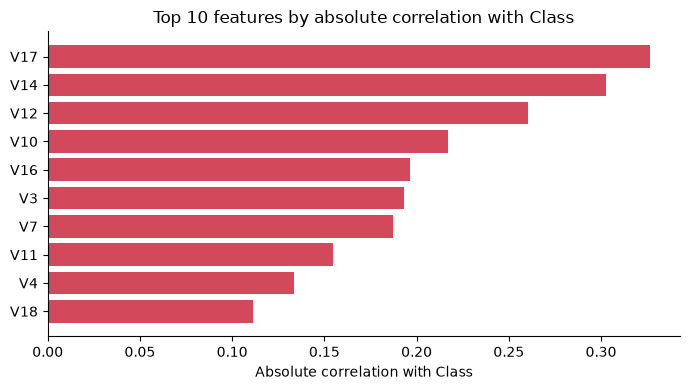

,correlation
V17,-0.326
V14,-0.303
V12,-0.261
V10,-0.217
V16,-0.197
V3,-0.193
V7,-0.187
V11,0.155
V4,0.133
V18,-0.111


In [14]:
feature_cols = [col for col in df.columns if col not in ["Class", "hour"]]
correlations = df[feature_cols].corrwith(df["Class"])
top10 = correlations.reindex(correlations.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top10.index[::-1], top10.abs().values[::-1], color="#d1495b")
ax.set_xlabel("Absolute correlation with Class")
ax.set_title("Top 10 features by absolute correlation with Class")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

top10.round(3).to_frame("correlation")

### Boxplots of the top 3 features by class

Outliers are hidden to keep the boxes readable.

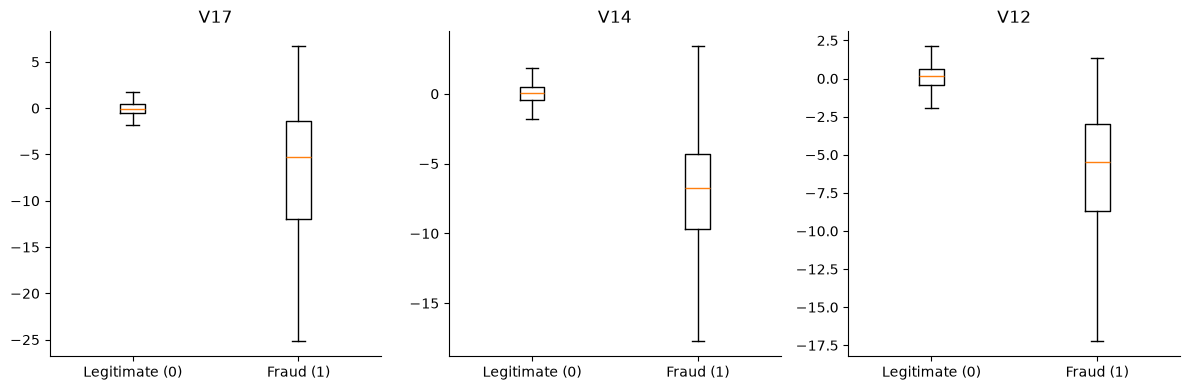

In [15]:
top3 = top10.index[:3]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, feature in zip(axes, top3):
    data = [df.loc[df["Class"] == 0, feature], df.loc[df["Class"] == 1, feature]]
    ax.boxplot(data, tick_labels=["Legitimate (0)", "Fraud (1)"], showfliers=False)
    ax.set_title(feature)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Takeaways

- **Use precision-recall metrics, not accuracy.** Fraud is only ~0.17% of the data, so we will focus on PR-AUC, precision, recall and F1.
- **Use a stratified train/test split** so both sets keep the same small share of fraud.
- **Handle the class imbalance**, for example with class weights in the Random Forest, and tune the decision threshold instead of using 0.5 by default.
- **Apply `log1p` to `Amount`.** It is very skewed; this matters little for a Random Forest but keeps the feature easier to inspect and compare.
- **V17, V14 and V12 separate the classes clearly** (fraud values are much lower). Keep all features for now, and check feature importance after training. Also decide what to do with the 1,081 duplicate rows before splitting.